# Gradient boosting from scratch

This notebook uses the two learning implementations in `automl.boosting`:

* `ScratchGradientBoosting*`: classic gradient boosting (Friedman, 2001); reproduces scikit-learn;
* `MiniXGB*`: second-order boosting with its own exact tree; reproduces `xgboost` with
  `tree_method="exact"`.

The tests in `tests/` prove the implementations match the libraries. Here we use them to *see*
how boosting learns and what each hyperparameter does:

1. how a sum of small trees approximates a function;
2. learning rate and the number of trees;
3. early stopping;
4. tree depth and the bias-variance trade-off;
5. regularisation: `gamma` and `reg_lambda`;
6. what is inside one XGBoost tree;
7. why the real library is fast.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import xgboost as xgb
from sklearn.datasets import load_diabetes, make_friedman1
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

from automl.boosting import MiniXGBRegressor, ScratchGradientBoostingRegressor

# Chart style: light surface, recessive grid, thin 2px lines. The three series colours are
# a colour-blind-safe set; every line is also labelled directly, never by colour alone.
SURFACE, INK, INK_2, GRID, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9", "#b9b8b1"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 110,
        "font.size": 10,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK_2,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlecolor": INK,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "xtick.color": INK_2,
        "ytick.color": INK_2,
        "text.color": INK,
        "lines.linewidth": 2,
        "legend.frameon": False,
    }
)


def rmse(y_true, y_pred):
    return mean_squared_error(y_true, y_pred) ** 0.5


def label_line_end(ax, x, y, text, dy=0.0):
    # Direct label at the end of a line, in text ink (the line itself carries the colour).
    ax.annotate(
        text,
        (x, y),
        xytext=(6, dy),
        textcoords="offset points",
        va="center",
        fontsize=9,
        color=INK_2,
    )

## 1. A sum of small trees

A one-dimensional toy problem: a noisy sine wave. Every tree here has depth 2 (at most four
steps), yet the sum of many of them follows the curve. The first trees capture the big shape,
later ones add finer and finer corrections.

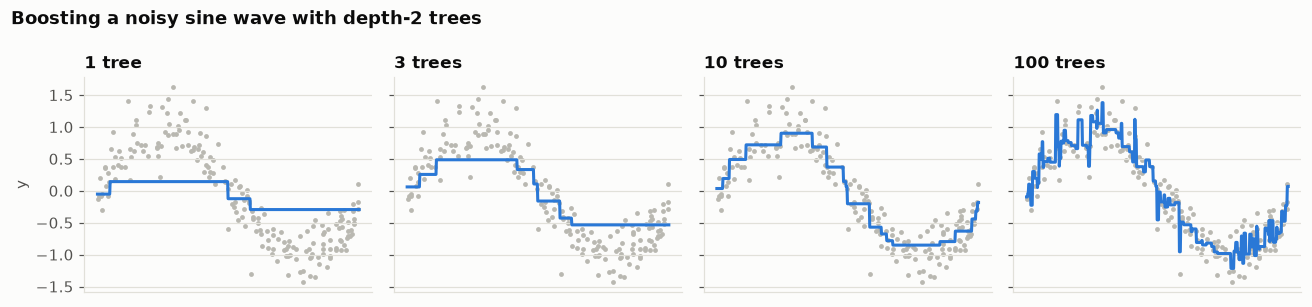

In [2]:
rng = np.random.default_rng(0)
x_toy = np.sort(rng.uniform(0, 6, 200))
y_toy = np.sin(x_toy) + rng.normal(0, 0.25, x_toy.size)
X_toy = x_toy.reshape(-1, 1)
grid = np.linspace(0, 6, 600).reshape(-1, 1)

model = ScratchGradientBoostingRegressor(
    n_estimators=100, learning_rate=0.3, max_depth=2, random_state=0
)
model.fit(X_toy, y_toy)
stages = list(model.staged_predict(grid))

fig, axes = plt.subplots(1, 4, figsize=(12, 2.8), sharey=True)
for ax, n_trees in zip(axes, [1, 3, 10, 100], strict=True):
    ax.scatter(x_toy, y_toy, s=10, color=MUTED, linewidths=0)
    ax.plot(grid[:, 0], stages[n_trees - 1], color=BLUE)
    ax.set_title(f"{n_trees} tree{'s' if n_trees > 1 else ''}")
    ax.set_xticks([])
axes[0].set_ylabel("y")
fig.suptitle(
    "Boosting a noisy sine wave with depth-2 trees",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=12,
)
fig.tight_layout()
plt.show()

## 2. Learning rate and the number of trees

From here on the data is the *diabetes* dataset bundled with scikit-learn (442 patients,
10 features, target: disease progression after one year). It is small and noisy, so
overfitting shows up quickly.

Each new tree is added with weight `learning_rate`. A large step learns fast but soon starts
fitting noise; a small step needs more trees but reaches a lower test error.

lr=0.5   best test RMSE 58.8 after 2 trees, 69.7 after 500
lr=0.1   best test RMSE 59.3 after 13 trees, 66.3 after 500
lr=0.02  best test RMSE 58.8 after 78 trees, 61.5 after 500


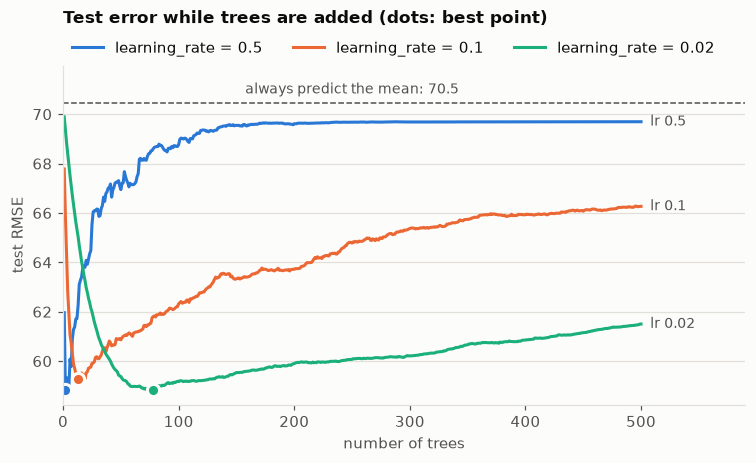

In [3]:
feature_names = load_diabetes().feature_names
X, y = load_diabetes(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
N_TREES = 500

curves = {}
for lr in (0.5, 0.1, 0.02):
    m = ScratchGradientBoostingRegressor(
        n_estimators=N_TREES, learning_rate=lr, max_depth=3, random_state=0
    )
    m.fit(X_train, y_train)
    curves[lr] = np.array([rmse(y_test, p) for p in m.staged_predict(X_test)])

trees = np.arange(1, N_TREES + 1)
fig, ax = plt.subplots(figsize=(8, 4))
for (lr, curve), color in zip(curves.items(), [BLUE, ORANGE, AQUA], strict=True):
    ax.plot(trees, curve, color=color, label=f"learning_rate = {lr}")
    best = int(np.argmin(curve))
    ax.plot(
        best + 1,
        curve[best],
        "o",
        color=color,
        markersize=8,
        markeredgecolor=SURFACE,
        markeredgewidth=2,
    )
    label_line_end(ax, N_TREES, curve[-1], f"lr {lr}")
    print(
        f"lr={lr:<5} best test RMSE {curve[best]:.1f} after {best + 1} trees, "
        f"{curve[-1]:.1f} after {N_TREES}"
    )
baseline = np.std(y_test)
ax.axhline(baseline, color=INK_2, linewidth=1, linestyle="--")
ax.annotate(
    f"always predict the mean: {baseline:.1f}",
    (N_TREES / 2, baseline),
    xytext=(0, 4),
    textcoords="offset points",
    ha="center",
    va="bottom",
    fontsize=9,
    color=INK_2,
)
ax.set_ylim(top=baseline + 1.5)
ax.set_xlabel("number of trees")
ax.set_ylabel("test RMSE")
ax.set_title("Test error while trees are added (dots: best point)", pad=28)
ax.set_xlim(0, N_TREES * 1.18)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=3, borderaxespad=0.2)
plt.show()

The training error keeps falling for ever, the test error does not. That gap is overfitting:

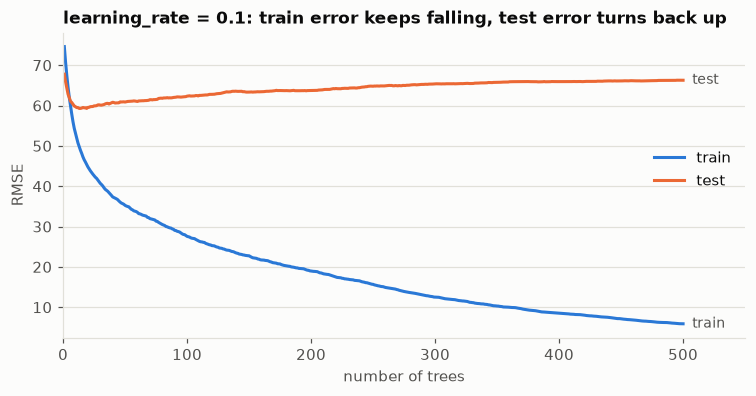

In [4]:
m = ScratchGradientBoostingRegressor(
    n_estimators=N_TREES, learning_rate=0.1, max_depth=3, random_state=0
)
m.fit(X_train, y_train)
train_curve = np.sqrt(m.train_loss_)  # train_loss_ is the MSE after every tree
test_curve = curves[0.1]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(trees, train_curve, color=BLUE, label="train")
ax.plot(trees, test_curve, color=ORANGE, label="test")
label_line_end(ax, N_TREES, train_curve[-1], "train")
label_line_end(ax, N_TREES, test_curve[-1], "test")
ax.set_xlabel("number of trees")
ax.set_ylabel("RMSE")
ax.set_title("learning_rate = 0.1: train error keeps falling, test error turns back up")
ax.set_xlim(0, N_TREES * 1.1)
ax.legend(loc="center right", bbox_to_anchor=(1.0, 0.55))
plt.show()

## 3. Early stopping

We cannot pick the number of trees by looking at the test set: then the test score is no
longer an honest estimate. Instead the training data is split once more, and a **validation**
set decides when to stop: training ends when the validation error has not improved for
`early_stopping_rounds` trees, and the best iteration is kept. The test set is used once,
at the very end.

This is the real `xgboost` API, the one the AutoML core will use.

stopped at tree 72 of 2000 (training ran 122 trees, then gave up)
test RMSE with early stopping: 61.3
test RMSE with all 2000 trees: 69.5


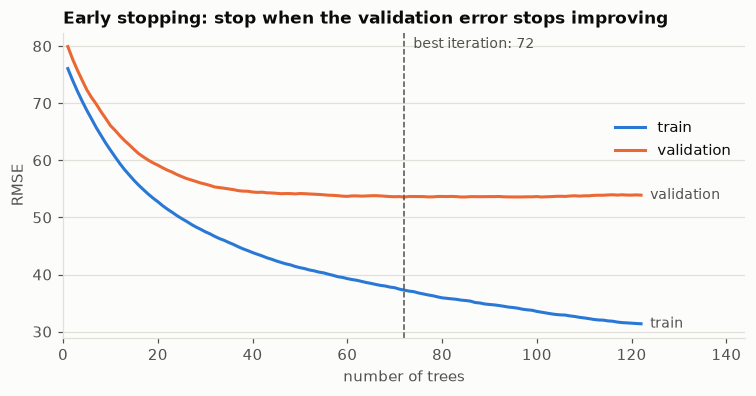

In [5]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=0)

stopped = xgb.XGBRegressor(
    n_estimators=2000, learning_rate=0.05, max_depth=3, early_stopping_rounds=50, eval_metric="rmse"
)
stopped.fit(X_fit, y_fit, eval_set=[(X_fit, y_fit), (X_val, y_val)], verbose=False)
history = stopped.evals_result()
best = stopped.best_iteration

full = xgb.XGBRegressor(n_estimators=2000, learning_rate=0.05, max_depth=3).fit(X_fit, y_fit)
print(
    f"stopped at tree {best + 1} of 2000 "
    f"(training ran {len(history['validation_1']['rmse'])} trees, then gave up)"
)
print(f"test RMSE with early stopping: {rmse(y_test, stopped.predict(X_test)):.1f}")
print(f"test RMSE with all 2000 trees: {rmse(y_test, full.predict(X_test)):.1f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
steps = np.arange(1, len(history["validation_0"]["rmse"]) + 1)
ax.plot(steps, history["validation_0"]["rmse"], color=BLUE, label="train")
ax.plot(steps, history["validation_1"]["rmse"], color=ORANGE, label="validation")
ax.axvline(best + 1, color=INK_2, linewidth=1, linestyle="--")
ax.annotate(
    f"best iteration: {best + 1}",
    (best + 1, ax.get_ylim()[1]),
    xytext=(6, -10),
    textcoords="offset points",
    fontsize=9,
    color=INK_2,
)
label_line_end(ax, steps[-1], history["validation_0"]["rmse"][-1], "train")
label_line_end(ax, steps[-1], history["validation_1"]["rmse"][-1], "validation")
ax.set_xlabel("number of trees")
ax.set_ylabel("RMSE")
ax.set_title("Early stopping: stop when the validation error stops improving")
ax.set_xlim(0, steps[-1] * 1.18)
ax.legend(loc="center right", bbox_to_anchor=(1.0, 0.65))
plt.show()

## 4. Tree depth: bias vs. variance

Shallow trees (depth 1 = "stumps") can only add one feature at a time: they underfit when
features interact. Deep trees fit interactions but also noise. For every depth below, the
number of trees is chosen by early stopping on the validation set, so each depth gets its
best shot.

(The training error at depth 8 is higher than at depth 7 because early stopping kept fewer
trees there.)

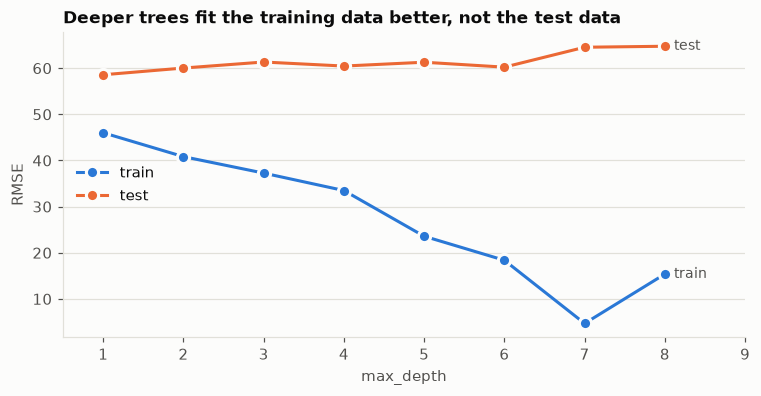

In [6]:
depths = range(1, 9)
train_err, test_err = [], []
for depth in depths:
    m = xgb.XGBRegressor(
        n_estimators=2000, learning_rate=0.05, max_depth=depth, early_stopping_rounds=50
    )
    m.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)
    train_err.append(rmse(y_fit, m.predict(X_fit)))
    test_err.append(rmse(y_test, m.predict(X_test)))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(
    depths,
    train_err,
    "o-",
    color=BLUE,
    label="train",
    markersize=8,
    markeredgecolor=SURFACE,
    markeredgewidth=2,
)
ax.plot(
    depths,
    test_err,
    "o-",
    color=ORANGE,
    label="test",
    markersize=8,
    markeredgecolor=SURFACE,
    markeredgewidth=2,
)
label_line_end(ax, depths[-1], train_err[-1], "train")
label_line_end(ax, depths[-1], test_err[-1], "test")
ax.set_xlabel("max_depth")
ax.set_ylabel("RMSE")
ax.set_title("Deeper trees fit the training data better, not the test data")
ax.set_xlim(0.5, 9)
ax.legend(loc="center left")
plt.show()

On this dataset the best test error comes from the shallowest trees: disease progression is
mostly a sum of separate effects (BMI, blood pressure, serum values) with little interaction.
On data with strong interactions the curve would bottom out deeper.

## 5. Regularisation: `gamma` and `reg_lambda`

Both live directly in the XGBoost formulas (see `mini_xgboost.py`):

* `gamma` is the minimum gain a split must bring, otherwise it is pruned: trees get smaller;
* `reg_lambda` is added to the hessian sum `H` in `weight = -G / (H + lambda)`: leaf values
  shrink, and splits on a handful of rows look less attractive.

Here we use our own `MiniXGBRegressor`, so we can count the leaves it actually grows.

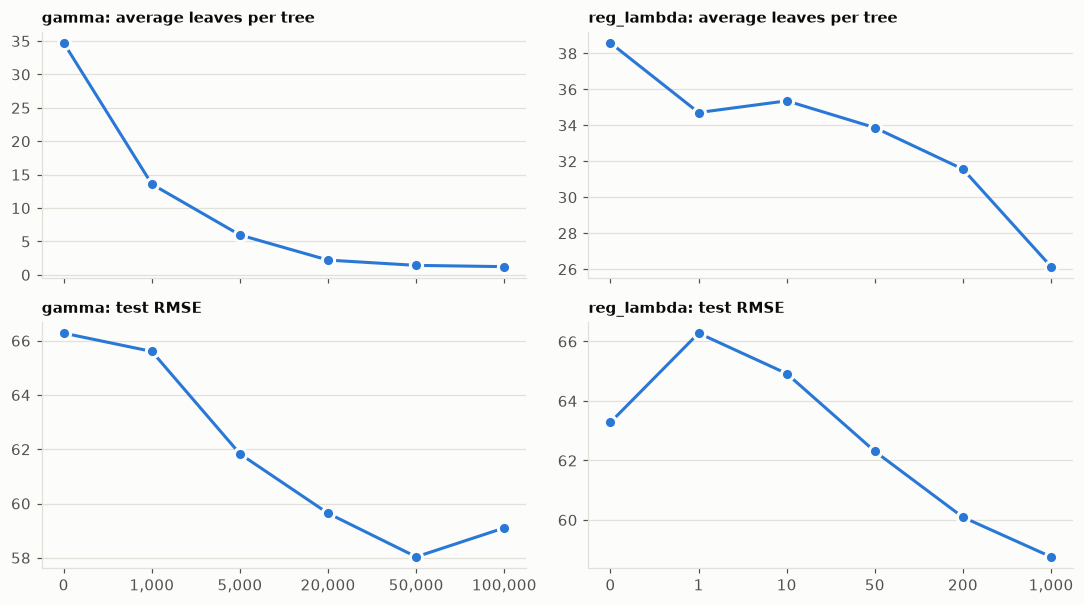

In [7]:
def sweep(param, values):
    leaves, errors = [], []
    for value in values:
        m = MiniXGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=6, **{param: value})
        m.fit(X_train, y_train)
        leaves.append(np.mean([t.n_leaves for t in m.trees_]))
        errors.append(rmse(y_test, m.predict(X_test)))
    return leaves, errors


gammas = [0, 1_000, 5_000, 20_000, 50_000, 100_000]
lambdas = [0, 1, 10, 50, 200, 1000]
gamma_leaves, gamma_err = sweep("gamma", gammas)
lambda_leaves, lambda_err = sweep("reg_lambda", lambdas)

fig, axes = plt.subplots(2, 2, figsize=(10, 5.6), sharex="col")
panels = [
    (axes[0, 0], gammas, gamma_leaves, "gamma: average leaves per tree"),
    (axes[1, 0], gammas, gamma_err, "gamma: test RMSE"),
    (axes[0, 1], lambdas, lambda_leaves, "reg_lambda: average leaves per tree"),
    (axes[1, 1], lambdas, lambda_err, "reg_lambda: test RMSE"),
]
for ax, xs, ys, title in panels:
    positions = np.arange(len(xs))
    ax.plot(
        positions, ys, "o-", color=BLUE, markersize=8, markeredgecolor=SURFACE, markeredgewidth=2
    )
    ax.set_title(title, fontsize=10)
    ax.set_xticks(positions, [f"{v:,}" for v in xs])
fig.tight_layout()
plt.show()

Two things to notice.

First, the number of trees is fixed at 100 with no early stopping, so the unregularised model
overfits (see section 2). Stronger regularisation slows learning down, and part of its effect
here is the same as stopping earlier. That is also why the curve for `reg_lambda` is not
smooth: regularisation and the number of trees have to be tuned *together*.

Second, the scale of `gamma`: it is compared with the gain, which is measured in units of the
squared gradient (the first split in section 6 gains about 660,000). For a target in the
hundreds, as here, useful values are in the tens of thousands; for a 0/1 classification target
they are around 0.1-10. That is why a fixed default search
range for `gamma` does not work for every dataset, and why the AutoML search space will
scale it to the data.

## 6. Inside one tree

`to_text()` prints a tree of the `MiniXGBRegressor`: the split, its gain, where missing
values go, and the leaf values (already multiplied by the learning rate). The very first tree
splits on the strongest signal in the data.

In [8]:
first_tree = MiniXGBRegressor(n_estimators=1, max_depth=2).fit(X_train, y_train).trees_[0]
print(first_tree.to_text(feature_names))

[s5 < 0.02166] gain = 661201.819, missing -> left
    [bmi < 0.005111] gain = 208014.089, missing -> left
        leaf = -14.5516
        leaf = 6.2011
    [bmi < 0.01319] gain = 145761.767, missing -> left
        leaf = 6.0230
        leaf = 28.6946


`bmi` (body mass index) and `s5` (a blood serum measurement) are indeed the two strongest
predictors of disease progression in this dataset.

## 7. Why the real library is fast

Same algorithm, three implementations, growing data. Both axes are logarithmic.

* `mini-xgb`: our Python code, exact search, one sort per feature per node;
* `xgb exact`: the same algorithm in C++ with multithreading;
* `xgb hist`: the default method. Every feature is bucketed once into at most 256 bins, and
  split search only scans bin totals instead of every distinct value.

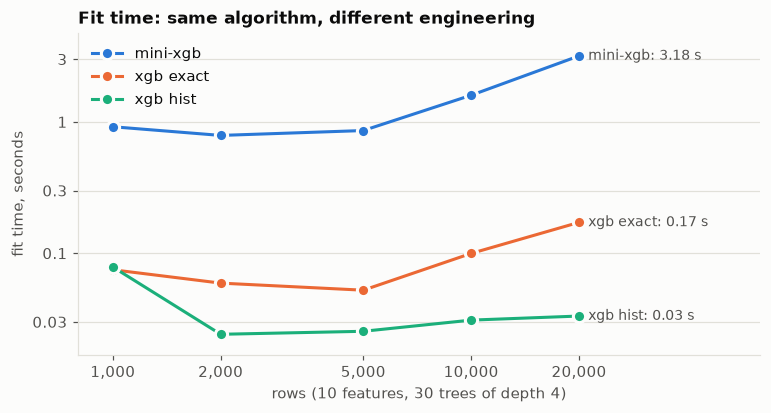

at 20,000 rows xgb hist is 96x faster than our Python version


In [9]:
sizes = [1_000, 2_000, 5_000, 10_000, 20_000]
params = {"n_estimators": 30, "max_depth": 4, "learning_rate": 0.3}
timings = {"mini-xgb": [], "xgb exact": [], "xgb hist": []}
for n in sizes:
    X_big, y_big = make_friedman1(n_samples=n, n_features=10, noise=1.0, random_state=0)
    for name, model in [
        ("mini-xgb", MiniXGBRegressor(**params)),
        ("xgb exact", xgb.XGBRegressor(**params, tree_method="exact")),
        ("xgb hist", xgb.XGBRegressor(**params)),
    ]:
        start = time.perf_counter()
        model.fit(X_big, y_big)
        timings[name].append(time.perf_counter() - start)

fig, ax = plt.subplots(figsize=(8, 3.8))
for (name, seconds), color in zip(timings.items(), [BLUE, ORANGE, AQUA], strict=True):
    ax.plot(
        sizes,
        seconds,
        "o-",
        color=color,
        label=name,
        markersize=8,
        markeredgecolor=SURFACE,
        markeredgewidth=2,
    )
    label_line_end(ax, sizes[-1], seconds[-1], f"{name}: {seconds[-1]:.2f} s")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(sizes, [f"{n:,}" for n in sizes])
ax.minorticks_off()
y_ticks = [0.01, 0.03, 0.1, 0.3, 1, 3, 10]
ax.set_yticks(y_ticks, [f"{t:g}" for t in y_ticks])
ax.set_ylim(
    min(min(v) for v in timings.values()) * 0.7, max(max(v) for v in timings.values()) * 1.5
)
ax.set_xlim(sizes[0] * 0.8, sizes[-1] * 3.2)
ax.set_xlabel("rows (10 features, 30 trees of depth 4)")
ax.set_ylabel("fit time, seconds")
ax.set_title("Fit time: same algorithm, different engineering")
ax.legend(loc="upper left")
plt.show()

ratio = timings["mini-xgb"][-1] / timings["xgb hist"][-1]
print(f"at {sizes[-1]:,} rows xgb hist is {ratio:.0f}x faster than our Python version")

## Takeaways

* Boosting is a sum of small trees; each one corrects what the previous ones got wrong.
* `learning_rate` and the number of trees go together: smaller steps need more trees and
  usually generalise better.
* The number of trees should be chosen by **early stopping on a validation set**, never on
  the test set.
* Depth controls interactions; shallow trees with many boosting rounds are a strong default.
* `gamma`, `reg_lambda`, `reg_alpha` and `min_child_weight` are all terms in the same two
  formulas: `-G / (H + lambda)` and the split gain. Their useful scale depends on the target.
* XGBoost's advantage over textbook boosting is the second-order split search plus serious
  engineering: C++, threads and histograms.

These points shape the AutoML core (stage 3): XGBoost with `hist`, early stopping on a
validation split, and a search space for Optuna scaled to the data.